# VC · Práctica 5 — Detección de emociones faciales (FER-2013)

Comparativa de **tres modelos clásicos de referencia** (Eigenfaces PCA+KNN, HOG+SVM y LBP+SVM), **nuestra CNN entrenada**
(en `VC_P5_CNN_entrenamiento.ipynb`) y **DeepFace**, sobre
[`ananthu017/emotion-detection-fer`](https://www.kaggle.com/datasets/ananthu017/emotion-detection-fer) (48×48, escala de grises, 7 clases).

**Índice**
1. Configuración y librerías
2. Reproducibilidad (seed)
3. Carga, exploración y adecuación del dataset (incl. `BALANCE_TRAIN`)
4. Utilidades de evaluación
5. Modelos clásicos de referencia
6. Nuestra CNN (cargada desde el notebook de entrenamiento)
7. DeepFace
8. Comparativa de todos los modelos
9. **Comparativa final: DeepFace vs. nuestra CNN**
10. Mejoras de nuestro modelo (por qué puntúa más)

## 1. Configuración y librerías

In [1]:
# (Opcional) instalación en el entorno Conda VC_P5. No se usa dlib.
# !pip install opencv-python mediapipe scikit-learn scikit-image tensorflow tf-keras deepface matplotlib joblib pandas tqdm

In [2]:
import os, time, json, random, warnings
from pathlib import Path
import ctypes, glob, os, site

_nv = os.path.join(site.getsitepackages()[0], "nvidia")
for _name in ["cusolver/lib/libcusolver.so.11", "curand/lib/libcurand.so.10"]:
    for _p in glob.glob(os.path.join(_nv, _name)):
        ctypes.CDLL(_p, mode=ctypes.RTLD_GLOBAL)

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
# DeepFace descarga sus pesos aquí (cámbialo si tu disco va justo de espacio)
os.environ.setdefault("DEEPFACE_HOME", os.path.abspath("./.deepface_cache"))
os.environ.setdefault("MPLCONFIGDIR", "/tmp/mpl_cache")

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from joblib import Parallel, delayed
from tqdm.auto import tqdm

from skimage.feature import hog, local_binary_pattern
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", category=UserWarning)

In [23]:
DATA_DIR = Path(
    r"/home/cris/Proyectos/computer-vision/image-dataset/prac5_dataset"
)  # <-- CAMBIAR: carpeta que contiene train/ y test/
TRAIN_DIR, TEST_DIR = DATA_DIR / "train", DATA_DIR / "test"

OUT_DIR = Path("outputs_p5")
MODELS_DIR = OUT_DIR / "models/v1"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
 
SEED = 42
IMG_SIZE = 48
VAL_SIZE = 0.20  # validación estratificada sacada de train
N_JOBS = (
    -1
)  # paralelismo para extraer características (la inferencia se mide con 1 hilo)

# Datos de entrenamiento (afecta a los modelos clásicos de ESTE notebook)
BALANCE_TRAIN = False  # True = submuestrea train a igual nº de imágenes por clase
PER_CLASS_CAP = (
    None  # None = igualar a la clase más pequeña; p.ej. 2000 = tope por clase
)
RUN_TAG = (
    "" if not BALANCE_TRAIN else f"_bal{PER_CLASS_CAP or 'min'}"
)  # sufijo para no pisar ficheros entre experimentos

# Modelos clásicos de referencia: los 3 más conocidos (características -> clasificador)
CLASSIC_PLAN = {
    "PCA": "KNN",  # Eigenfaces (Turk & Pentland)
    "HOG": "SVM",  # HOG + SVM  (Dalal & Triggs)
    "LBP": "SVM",
}  # LBP + SVM  (Ahonen et al.)
KNN_K_GRID = [5, 11, 21]
SVM_KIND = "rbf"  # "rbf" (SVC con subconjunto) | "linear" (LinearSVC con todo train)
SVM_MAX_TRAIN = (
    10_000  # nº máx. de muestras de train para SVC-RBF (coste ~ O(n^2..n^3))
)
SVM_C_GRID = [1, 10]

In [4]:
# Nuestra CNN: se ENTRENA en VC_P5_CNN_entrenamiento.ipynb y aquí solo se carga
def model_stem(seed, balance=False, cap=None):
    """Nombre del modelo guardado; debe coincidir con el del notebook de entrenamiento."""
    return f"cnn_fer_seed{seed}" + (f"_bal{cap if cap else 'min'}" if balance else "")


CNN_BAL_CAP = (
    None  # PER_CLASS_CAP usado al entrenar la CNN balanceada (None = clase más pequeña)
)
CNN_MODELS = {  # etiqueta -> nombre del .keras (los que no existan se omiten)
    "CNN": model_stem(SEED),
    "CNN balanceada": model_stem(SEED, True, CNN_BAL_CAP),
}
PRIMARY_CNN = "CNN"  # la que se enfrenta a DeepFace en la comparativa final

DETERMINISTIC = (
    False  # True = TensorFlow determinista (más lento); solo importa si se entrena aquí
)

# DeepFace: nº de imágenes de test (muestra estratificada, la MISMA para todos los modelos). None = todo test
DEEPFACE_N = 1000
DEEPFACE_DETECTOR = "skip"  # las imágenes ya son caras recortadas -> sin detector (un detector falla con 48x48)

# (la semilla se fija en la sección 2 con set_seed)
assert (
    TRAIN_DIR.is_dir() and TEST_DIR.is_dir()
), f"No encuentro train/ y test/ en {DATA_DIR}"
print("Dataset en:", DATA_DIR.resolve())

Dataset en: /home/cris/Proyectos/computer-vision/image-dataset/prac5_dataset


## 2. Reproducibilidad (seed)

Objetivo: que **cada ejecución del notebook dé exactamente lo mismo** (misma partición de datos, mismos subconjuntos y mismos modelos clásicos).

* Una única `SEED` (celda de configuración) alimenta todo el azar: `train_test_split(random_state=SEED)`, el balanceo por clase (`default_rng(SEED)`), `PCA`, `SVC`, la muestra de DeepFace…
* `set_seed()` fija **Python, NumPy y TensorFlow** y se vuelve a llamar al inicio de cada etapa con azar, de modo que re-ejecutar una celda suelta no cambia el resultado.
* `PYTHONHASHSEED` solo afecta a procesos hijos (los de `joblib`); el intérprete actual ya arrancó con su hash.
* `DETERMINISTIC=True` fuerza operaciones deterministas de TensorFlow (exacto, más lento). En este notebook la CNN **solo se carga**, así que solo importa si la entrenas aquí.
* La **huella (hash) del split** se imprime al crearlo: si coincide entre ejecuciones, la partición es idéntica.

In [5]:
import hashlib

def set_seed(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed); np.random.seed(seed)
    try:
        import tensorflow as tf
        tf.keras.utils.set_random_seed(seed)                 # python + numpy + TF a la vez
        if DETERMINISTIC:
            tf.config.experimental.enable_op_determinism()
    except ImportError:
        pass

def fingerprint(*arrays):
    """Huella corta de uno o varios arrays: sirve para comprobar que dos ejecuciones usan los mismos datos."""
    h = hashlib.md5()
    for a in arrays: h.update(np.ascontiguousarray(a).tobytes())
    return h.hexdigest()[:10]

set_seed(SEED)
print(f"Seed global: {SEED} | DETERMINISTIC={DETERMINISTIC}")

Seed global: 42 | DETERMINISTIC=False


## 3. Carga, exploración y adecuación del dataset
Las imágenes se leen con `np.fromfile` + `cv2.imdecode` para evitar problemas de OpenCV con rutas con tildes/espacios en Windows.

In [6]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}

def read_gray(path: Path) -> np.ndarray:
    data = np.fromfile(str(path), dtype=np.uint8)
    img = cv2.imdecode(data, cv2.IMREAD_GRAYSCALE)
    if img is not None and img.shape != (IMG_SIZE, IMG_SIZE):
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    return img

def load_split(split_dir: Path, class_names=None):
    """Devuelve X (N,48,48) uint8, y (N,) int y los nombres de clase (orden alfabético = índice)."""
    if class_names is None:
        class_names = sorted(p.name for p in split_dir.iterdir() if p.is_dir())
    X, y = [], []
    for idx, cname in enumerate(class_names):
        files = sorted(f for f in (split_dir / cname).iterdir() if f.suffix.lower() in IMG_EXT)
        for f in tqdm(files, desc=f"{split_dir.name}/{cname}", leave=False):
            img = read_gray(f)
            if img is not None:
                X.append(img); y.append(idx)
    return np.stack(X).astype(np.uint8), np.array(y, dtype=np.int64), class_names

X_full, y_full, CLASS_NAMES = load_split(TRAIN_DIR)
X_test, y_test, _ = load_split(TEST_DIR, CLASS_NAMES)
N_CLASSES = len(CLASS_NAMES)
print("Clases:", CLASS_NAMES)
print("train completo:", X_full.shape, "| test:", X_test.shape)

train/angry:   0%|          | 0/3995 [00:00<?, ?it/s]

train/disgusted:   0%|          | 0/436 [00:00<?, ?it/s]

train/fearful:   0%|          | 0/4097 [00:00<?, ?it/s]

train/happy:   0%|          | 0/7215 [00:00<?, ?it/s]

train/neutral:   0%|          | 0/4965 [00:00<?, ?it/s]

train/sad:   0%|          | 0/4830 [00:00<?, ?it/s]

... (5 outputs left out)

test/neutral:   0%|          | 0/1233 [00:00<?, ?it/s]

test/sad:   0%|          | 0/1247 [00:00<?, ?it/s]

test/surprised:   0%|          | 0/831 [00:00<?, ?it/s]

Clases: ['angry', 'disgusted', 'fearful', 'happy', 'neutral', 'sad', 'surprised']
train completo: (28709, 48, 48) | test: (7178, 48, 48)


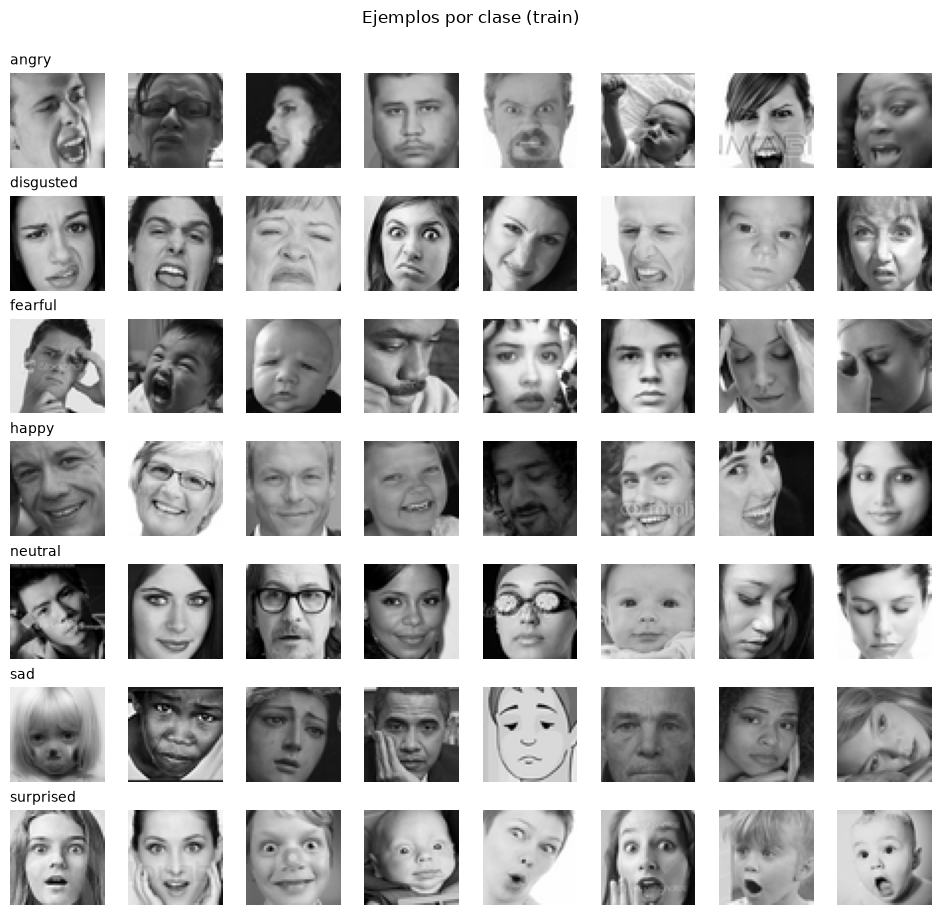

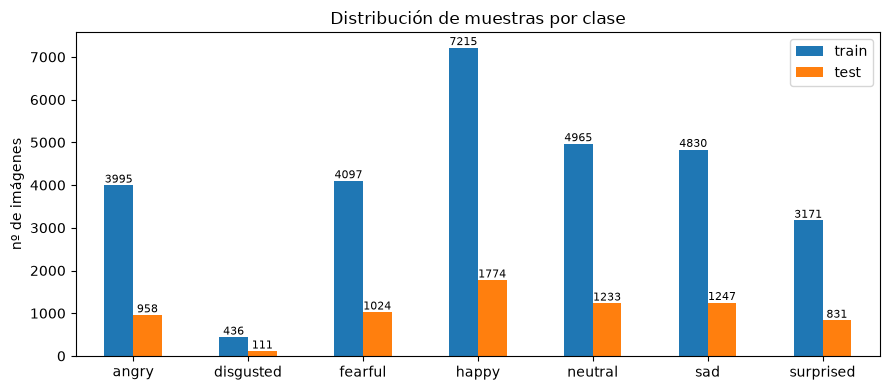

           train  test
angry       3995   958
disgusted    436   111
fearful     4097  1024
happy       7215  1774
neutral     4965  1233
sad         4830  1247
surprised   3171   831

Ratio de desbalanceo en train (máx/mín): 16.5x


In [7]:
# --- Ejemplos de cada clase ---
rng = np.random.default_rng(SEED)
n_show = 8
fig, axes = plt.subplots(N_CLASSES, n_show, figsize=(n_show * 1.2, N_CLASSES * 1.3))
for r, cname in enumerate(CLASS_NAMES):
    idxs = rng.choice(np.where(y_full == r)[0], n_show, replace=False)
    for c, i in enumerate(idxs):
        axes[r, c].imshow(X_full[i], cmap="gray", vmin=0, vmax=255)
        axes[r, c].axis("off")
    axes[r, 0].set_title(cname, loc="left", fontsize=10)
plt.suptitle("Ejemplos por clase (train)", y=1.0)
plt.tight_layout(); plt.show()

# --- Distribución de muestras en train y test ---
counts = pd.DataFrame({
    "train": np.bincount(y_full, minlength=N_CLASSES),
    "test":  np.bincount(y_test, minlength=N_CLASSES),
}, index=CLASS_NAMES)
ax = counts.plot(kind="bar", figsize=(9, 4), rot=0)
for cont in ax.containers: ax.bar_label(cont, fontsize=8)
ax.set_title("Distribución de muestras por clase"); ax.set_ylabel("nº de imágenes")
plt.tight_layout(); plt.show()
print(counts)
print(f"\nRatio de desbalanceo en train (máx/mín): {counts['train'].max() / counts['train'].min():.1f}x")

In [8]:
set_seed(SEED)

# --- Validación estratificada 80/20 desde train; test queda reservado SOLO para la evaluación final ---
idx_tr, idx_val = train_test_split(np.arange(len(y_full)), test_size=VAL_SIZE,
                                   stratify=y_full, random_state=SEED)
X_tr,  y_tr  = X_full[idx_tr],  y_full[idx_tr]
X_val, y_val = X_full[idx_val], y_full[idx_val]

# --- (Opcional) train balanceado: mismo nº de imágenes por clase. La validación NO se toca ---
def balanced_indices(y, cap=None, seed=SEED):
    rng = np.random.default_rng(seed)
    counts = np.bincount(y, minlength=N_CLASSES)
    cap = cap or counts.min()
    sel = np.concatenate([rng.choice(np.where(y == c)[0], min(cap, counts[c]), replace=False)
                          for c in range(N_CLASSES)])
    rng.shuffle(sel)
    return sel

if BALANCE_TRAIN:
    sel = balanced_indices(y_tr, PER_CLASS_CAP)
    X_tr, y_tr = X_tr[sel], y_tr[sel]
    print(f"** TRAIN BALANCEADO ** ({PER_CLASS_CAP or 'clase más pequeña'} por clase)")

print(f"train: {len(y_tr)} | val: {len(y_val)} | test: {len(y_test)}")
print("Huella del split (debe ser idéntica en cada ejecución):", fingerprint(idx_val), "| train:", fingerprint(y_tr))

# --- class_weight (solo con el train usado para entrenar); lo usan los SVM mediante class_weight="balanced" ---
cw = compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=y_tr)
CLASS_WEIGHTS = {i: float(w) for i, w in enumerate(cw)}
print(pd.DataFrame({"train": np.bincount(y_tr, minlength=N_CLASSES), "val": np.bincount(y_val, minlength=N_CLASSES),
                    "class_weight": np.round(list(CLASS_WEIGHTS.values()), 2)}, index=CLASS_NAMES).T)

train: 22967 | val: 5742 | test: 7178
Huella del split (debe ser idéntica en cada ejecución): 8bc7fcb2f1 | train: c2bd539bfa
                angry  disgusted  fearful    happy  neutral      sad  \
train         3196.00      349.0   3277.0  5772.00  3972.00  3864.00   
val            799.00       87.0    820.0  1443.00   993.00   966.00   
class_weight     1.03        9.4      1.0     0.57     0.83     0.85   

              surprised  
train           2537.00  
val              634.00  
class_weight       1.29  


## 4. Utilidades de evaluación
* `timed_predict`: devuelve predicciones y **ms medios por imagen** (pipeline completo: extracción de características + clasificación). Hace un pequeño calentamiento previo.
* `evaluate`: Accuracy, F1 macro/weighted, informe por clase y registro en `RESULTS`.
* `plot_confusions`: matrices de confusión normalizadas por fila.

In [9]:
RESULTS, PREDS = [], {}      # PREDS[(modelo, conjunto)] = y_pred

def timed_predict(predict_fn, X, warmup=16):
    predict_fn(X[:warmup])                       # calentamiento (carga de pesos, caches...)
    t0 = time.perf_counter()
    y_pred = predict_fn(X)
    ms_per_img = (time.perf_counter() - t0) / len(X) * 1000
    return np.asarray(y_pred), ms_per_img

def evaluate(name, family, y_true, y_pred, ms_img, subset, verbose=True):
    labels = list(range(N_CLASSES))
    row = dict(modelo=name, familia=family, conjunto=subset, n=len(y_true),
               accuracy=accuracy_score(y_true, y_pred),
               f1_macro=f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0),
               f1_weighted=f1_score(y_true, y_pred, labels=labels, average="weighted", zero_division=0),
               ms_img=ms_img)
    RESULTS.append(row); PREDS[(name, subset)] = np.asarray(y_pred)
    if verbose:
        print(f"[{name} | {subset}] acc={row['accuracy']:.4f}  F1-macro={row['f1_macro']:.4f}  "
              f"F1-weighted={row['f1_weighted']:.4f}  {ms_img:.3f} ms/img")
        print(classification_report(y_true, y_pred, labels=labels, target_names=CLASS_NAMES, zero_division=0))
    return row

def plot_confusions(names, y_true, subset, ncols=3):
    nrows = int(np.ceil(len(names) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 4.8 * nrows))
    for ax, name in zip(np.atleast_1d(axes).ravel(), names):
        cm = confusion_matrix(y_true, PREDS[(name, subset)], labels=range(N_CLASSES), normalize="true")
        ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", colorbar=False,
                                                                    xticks_rotation=45, values_format=".2f")
        ax.set_title(f"{name} ({subset})")
    for ax in np.atleast_1d(axes).ravel()[len(names):]: ax.axis("off")
    plt.tight_layout(); plt.show()

## 5. Modelos clásicos de referencia
Solo **tres modelos, los más conocidos** en reconocimiento facial, cada uno con su combinación habitual (editable con `CLASSIC_PLAN`):

| Modelo | Características | Clasificador |
|---|---|---|
| **Eigenfaces** | PCA conservando el 95 % de la varianza | KNN |
| **HOG + SVM** | HOG (9 orientaciones, celdas 6×6, bloques 2×2) | SVM |
| **LBP + SVM** | LBP uniforme (P=8, R=1), histogramas en rejilla 6×6 | SVM |

Todo se ajusta **solo con el split de entrenamiento** (y con `BALANCE_TRAIN=True`, con el train balanceado). Cada extractor es una clase con `__call__(X, n_jobs)`; en entrenamiento se usan todos los núcleos y en **inferencia 1 hilo**, para que el tiempo por imagen sea comparable.

In [10]:
def _flat(X): return X.reshape(len(X), -1).astype(np.float32) / 255.0

class PCAFeatures:
    def __init__(self, pca): self.pca = pca
    def __call__(self, X, n_jobs=1): return self.pca.transform(_flat(X))

def _hog1(im):
    return hog(im, orientations=9, pixels_per_cell=(6, 6), cells_per_block=(2, 2),
               block_norm="L2-Hys", feature_vector=True)

def _lbp1(im, P=8, R=1, grid=(6, 6)):
    lbp = local_binary_pattern(im, P, R, method="uniform")        # valores 0..P+1
    gh, gw = im.shape[0] // grid[0], im.shape[1] // grid[1]
    feats = []
    for i in range(grid[0]):
        for j in range(grid[1]):
            cell = lbp[i*gh:(i+1)*gh, j*gw:(j+1)*gw].astype(np.int64).ravel()
            feats.append(np.bincount(cell, minlength=P + 2) / cell.size)
    return np.concatenate(feats)

def _extract(fn, X, n_jobs):
    if n_jobs == 1:
        return np.asarray([fn(im) for im in X], dtype=np.float32)
    return np.asarray(Parallel(n_jobs=n_jobs, batch_size=256)(delayed(fn)(im) for im in X), dtype=np.float32)

class HOGFeatures:
    def __call__(self, X, n_jobs=1): return _extract(_hog1, X, n_jobs)

class LBPFeatures:
    def __call__(self, X, n_jobs=1): return _extract(_lbp1, X, n_jobs)

class ClassicModel:
    """extractor -> (scaler opcional) -> clasificador. predict() recibe imágenes (N,48,48) uint8."""
    def __init__(self, name, extractor, scaler, clf):
        self.name, self.extractor, self.scaler, self.clf = name, extractor, scaler, clf
    def features(self, X, n_jobs=1):
        F = self.extractor(X, n_jobs)
        return self.scaler.transform(F) if self.scaler is not None else F
    def predict(self, X): return self.clf.predict(self.features(X, 1))

set_seed(SEED)
EXTRACTORS = {}
if "PCA" in CLASSIC_PLAN:    # PCA al 95 % de varianza (ajustado solo con X_tr)
    t0 = time.time()
    pca = PCA(n_components=0.95, svd_solver="full", random_state=SEED).fit(_flat(X_tr))
    print(f"PCA: {pca.n_components_} componentes para el 95% de varianza ({time.time()-t0:.1f}s)")
    EXTRACTORS["PCA"] = PCAFeatures(pca)
if "HOG" in CLASSIC_PLAN: EXTRACTORS["HOG"] = HOGFeatures()
if "LBP" in CLASSIC_PLAN: EXTRACTORS["LBP"] = LBPFeatures()

F_tr, F_val = {}, {}
for k, ext in EXTRACTORS.items():
    t0 = time.time()
    F_tr[k], F_val[k] = ext(X_tr, N_JOBS), ext(X_val, N_JOBS)
    print(f"{k}: {F_tr[k].shape[1]} características  ({time.time()-t0:.1f}s)")

PCA: 252 componentes para el 95% de varianza (12.2s)
PCA: 252 características  (0.2s)
HOG: 1764 características  (3.4s)
LBP: 360 características  (1.7s)


In [11]:
set_seed(SEED)
CLASSIC = {}                                  # nombre -> ClassicModel (ya entrenado)
SUFFIX = " (bal)" if BALANCE_TRAIN else ""    # marca en las tablas si el train está balanceado

# ---------------- Subconjunto para SVM ----------------
# JUSTIFICACIÓN DE RENDIMIENTO: un SVC con kernel RBF escala entre O(n^2) y O(n^3) con el nº de muestras;
# con ~23k imágenes de train y 1.7k características (HOG) es muy lento. Por eso:
#   * SVM_KIND="rbf"    -> SVC entrenado con un SUBCONJUNTO ESTRATIFICADO de SVM_MAX_TRAIN muestras de train
#   * SVM_KIND="linear" -> LinearSVC con TODO train (escala ~lineal, algo menos expresivo)
# En ambos casos class_weight="balanced" y C elegido sobre la validación (macro-F1).
if SVM_KIND == "rbf" and len(y_tr) > SVM_MAX_TRAIN:
    sub_idx, _ = train_test_split(np.arange(len(y_tr)), train_size=SVM_MAX_TRAIN, stratify=y_tr, random_state=SEED)
else:
    sub_idx = np.arange(len(y_tr))
print(f"SVM ({SVM_KIND}): entrenando con {len(sub_idx)} de {len(y_tr)} muestras de train\n")

def make_svm(C):
    if SVM_KIND == "linear":
        return LinearSVC(C=C, class_weight="balanced", dual="auto", max_iter=5000, random_state=SEED)
    return SVC(kernel="rbf", C=C, gamma="scale", class_weight="balanced", cache_size=1000, random_state=SEED)

for feat, kind in CLASSIC_PLAN.items():
    name = f"{feat}+{kind}" + SUFFIX
    if kind == "KNN":
        # k elegido sobre la validación (macro-F1). KNN no admite class_weight.
        best = (-1, None)
        for k in KNN_K_GRID:
            knn = KNeighborsClassifier(n_neighbors=k, n_jobs=N_JOBS).fit(F_tr[feat], y_tr)
            f1 = f1_score(y_val, knn.predict(F_val[feat]), average="macro")
            print(f"KNN-{feat}  k={k:>2}  val F1-macro={f1:.4f}")
            if f1 > best[0]: best = (f1, k)
        knn = KNeighborsClassifier(n_neighbors=best[1], n_jobs=1).fit(F_tr[feat], y_tr)   # n_jobs=1 -> inferencia justa
        CLASSIC[name] = ClassicModel(name, EXTRACTORS[feat], None, knn)
        print(f"  -> {name}: k={best[1]}\n")
    elif kind == "SVM":
        scaler = None if feat == "PCA" else StandardScaler().fit(F_tr[feat][sub_idx])   # PCA: gamma="scale" ya se adapta
        tf_ = (lambda F, sc=scaler: sc.transform(F)) if scaler is not None else (lambda F: F)
        Xs, Xv = tf_(F_tr[feat][sub_idx]), tf_(F_val[feat])
        best = (-1, None, None)
        for C in SVM_C_GRID:
            t0 = time.time()
            svm = make_svm(C).fit(Xs, y_tr[sub_idx])
            f1 = f1_score(y_val, svm.predict(Xv), average="macro")
            print(f"SVM-{feat}  C={C:<4} val F1-macro={f1:.4f}  ({time.time()-t0:.0f}s)")
            if f1 > best[0]: best = (f1, C, svm)
        CLASSIC[name] = ClassicModel(name, EXTRACTORS[feat], scaler, best[2])
        print(f"  -> {name}: C={best[1]}\n")
    else:
        raise ValueError(f"Clasificador desconocido en CLASSIC_PLAN: {kind}")

SVM (rbf): entrenando con 10000 de 22967 muestras de train

KNN-PCA  k= 5  val F1-macro=0.3110
KNN-PCA  k=11  val F1-macro=0.2716
KNN-PCA  k=21  val F1-macro=0.2472
  -> PCA+KNN: k=5

SVM-HOG  C=1    val F1-macro=0.4473  (136s)
SVM-HOG  C=10   val F1-macro=0.4608  (158s)
  -> HOG+SVM: C=10

SVM-LBP  C=1    val F1-macro=0.3338  (19s)
SVM-LBP  C=10   val F1-macro=0.3423  (21s)
  -> LBP+SVM: C=10



In [12]:
# ---------------- Evaluación final en TEST (conjunto completo) + guardado ----------------
PREDICT_FNS = {}     # nombre -> (familia, función imágenes -> etiquetas); se reutiliza en la comparativa con DeepFace
for name, model in CLASSIC.items():
    PREDICT_FNS[name] = ("Clásico", model.predict)
    y_pred, ms = timed_predict(model.predict, X_test)
    evaluate(name, "Clásico", y_test, y_pred, ms, "completo", verbose=False)
    base = name.replace(SUFFIX, "").replace("+", "_")
    joblib.dump(model, MODELS_DIR / f"{base}{RUN_TAG}.joblib")

pd.DataFrame(RESULTS).round(4)

,modelo,familia,conjunto,n,accuracy,f1_macro,f1_weighted,ms_img
0,PCA+KNN,Clásico,completo,7178,0.3189,0.3032,0.3158,0.0512
1,HOG+SVM,Clásico,completo,7178,0.4994,0.4601,0.4918,8.4684
2,LBP+SVM,Clásico,completo,7178,0.3983,0.3662,0.3913,1.8600


## 6. Nuestra CNN (entrenada en `VC_P5_CNN_entrenamiento.ipynb`)
Aquí **no se entrena**: se cargan los `.keras` guardados en `outputs_p5/models/` (ejecuta ambos notebooks desde la misma carpeta).

* `CNN`: entrenada con todo el train (con `class_weight`).
* `CNN balanceada` (opcional): entrenada con `BALANCE_TRAIN=True`, para ver cómo cambian los resultados al igualar el nº de imágenes por clase. Si no existe el archivo, se omite.

Se muestra la configuración con la que se entrenó cada una (leída de su `_config.json`) para que la comparación sea trazable.

In [24]:
import tensorflow as tf
from tensorflow import keras

print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

def to_cnn_input(X): return X[..., None].astype("float32")      # (N,48,48,1), rango 0-255

CNN_LOADED, CNN_INFO = {}, {}
for label, stem in CNN_MODELS.items():
    path = MODELS_DIR / f"{stem}.keras"
    if not path.exists():
        print(f"[{label}] NO encontrado: {path.name} -> entrénalo en VC_P5_CNN_entrenamiento.ipynb (se omite)")
        continue
    CNN_LOADED[label] = keras.models.load_model(path)
    cfg = MODELS_DIR / f"{stem}_config.json"
    CNN_INFO[label] = json.load(open(cfg)) if cfg.exists() else {}
    print(f"[{label}] cargado: {path.name}")

assert PRIMARY_CNN in CNN_LOADED, f"Falta la CNN principal ({CNN_MODELS[PRIMARY_CNN]}.keras): entrénala primero."

cols = ["seed", "balance_train", "per_class_cap", "dropouts", "head_dropout", "weight_decay",
        "best_epoch", "val_accuracy", "val_f1_macro"]
display(pd.DataFrame(CNN_INFO).T.reindex(columns=cols))

TensorFlow 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
[CNN] cargado: cnn_fer_seed42.keras
[CNN balanceada] NO encontrado: cnn_fer_seed42_balmin.keras -> entrénalo en VC_P5_CNN_entrenamiento.ipynb (se omite)


,seed,balance_train,per_class_cap,dropouts,head_dropout,weight_decay,best_epoch,val_accuracy,val_f1_macro
CNN,42,False,None,"[0.1, 0.15, 0.2, 0.25]",0.4,0.0001,37,0.630791,0.61388


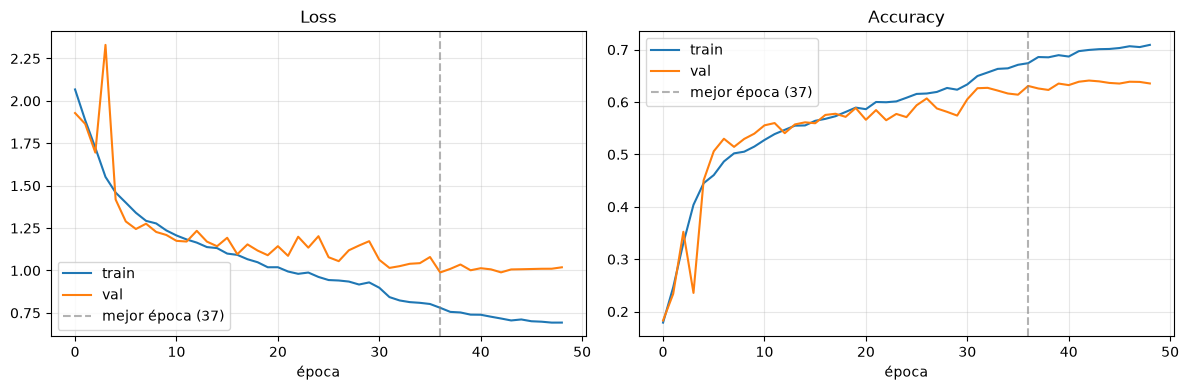

In [25]:
# Curvas de entrenamiento de la CNN principal (guardadas por el notebook de entrenamiento)
hist_path = MODELS_DIR / f"{CNN_MODELS[PRIMARY_CNN]}_history.csv"
if hist_path.exists():
    h = pd.read_csv(hist_path)
    best_ep = int(h["val_loss"].idxmin())
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="val"); ax[0].set_title("Loss")
    ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="val"); ax[1].set_title("Accuracy")
    for a in ax:
        a.axvline(best_ep, color="gray", ls="--", alpha=.6, label=f"mejor época ({best_ep + 1})")
        a.set_xlabel("época"); a.legend(); a.grid(alpha=.3)
    plt.tight_layout(); plt.show()
else:
    print("No hay historial de entrenamiento:", hist_path.name)

In [26]:
# --- Evaluación de las CNN en TEST (completo) ---
def make_cnn_predict(model):
    def _predict(X):
        return np.argmax(model.predict(to_cnn_input(X), batch_size=256, verbose=0), axis=1)
    return _predict

for label, model in CNN_LOADED.items():
    fn = make_cnn_predict(model)
    PREDICT_FNS[label] = ("CNN propia", fn)
    y_pred, ms = timed_predict(fn, X_test)
    evaluate(label, "CNN propia", y_test, y_pred, ms, "completo", verbose=(label == PRIMARY_CNN))

# Latencia imagen a imagen (caso webcam, batch=1) de la CNN principal
m = CNN_LOADED[PRIMARY_CNN]
sample = to_cnn_input(X_test[:200]); m(sample[:1], training=False)      # calentamiento
t0 = time.perf_counter()
for im in sample: m(im[None], training=False)
CNN_LAT_BS1 = (time.perf_counter() - t0) / len(sample) * 1000
print(f"{PRIMARY_CNN}: latencia con batch=1: {CNN_LAT_BS1:.2f} ms/img")

[CNN | completo] acc=0.6332  F1-macro=0.6194  F1-weighted=0.6361  0.136 ms/img
              precision    recall  f1-score   support

       angry       0.57      0.56      0.56       958
   disgusted       0.58      0.64      0.61       111
     fearful       0.46      0.44      0.45      1024
       happy       0.89      0.79      0.84      1774
     neutral       0.54      0.66      0.59      1233
         sad       0.52      0.51      0.51      1247
   surprised       0.77      0.77      0.77       831

    accuracy                           0.63      7178
   macro avg       0.62      0.62      0.62      7178
weighted avg       0.64      0.63      0.64      7178

CNN: latencia con batch=1: 15.55 ms/img


## 7. DeepFace
`DeepFace.analyze(actions=['emotion'], enforce_detection=False)` sobre una **muestra estratificada del test** (la misma para todos los modelos en la comparativa directa).

**Mapeo de etiquetas.** El dataset usa `disgusted / fearful / surprised` y DeepFace devuelve `disgust / fear / surprise`.
Se normaliza todo al vocabulario del dataset (índices de `CLASS_NAMES`) para que las matrices de confusión cuadren.

`detector_backend="skip"`: las imágenes ya son caras recortadas de 48×48 y un detector (opencv, retinaface…) suele no encontrarlas a esa resolución; con `skip` DeepFace usa la imagen entera como cara.

In [27]:
from deepface import DeepFace

set_seed(SEED)

DEEPFACE_TO_DATASET = {"angry": "angry", "disgust": "disgusted", "fear": "fearful",
                       "happy": "happy", "neutral": "neutral", "sad": "sad", "surprise": "surprised"}
assert set(DEEPFACE_TO_DATASET.values()) == set(CLASS_NAMES), \
    f"Las clases del dataset {CLASS_NAMES} no coinciden con el mapeo de DeepFace"
DF2IDX = {df_lbl: CLASS_NAMES.index(ds_lbl) for df_lbl, ds_lbl in DEEPFACE_TO_DATASET.items()}
print("Mapeo DeepFace -> índice:", DF2IDX)

# --- Muestra estratificada (misma para TODOS los modelos de la comparativa) ---
if DEEPFACE_N and DEEPFACE_N < len(y_test):
    idx_s, _ = train_test_split(np.arange(len(y_test)), train_size=DEEPFACE_N, stratify=y_test, random_state=SEED)
else:
    idx_s = np.arange(len(y_test))
X_s, y_s = X_test[idx_s], y_test[idx_s]
print("Muestra de comparación:", len(y_s), "imágenes | por clase:", dict(zip(CLASS_NAMES, np.bincount(y_s, minlength=N_CLASSES))))

DF_ERRORS = 0
def deepface_predict(X):
    global DF_ERRORS
    preds = []
    for im in tqdm(X, desc="DeepFace", leave=False):
        bgr = cv2.cvtColor(im, cv2.COLOR_GRAY2BGR)           # DeepFace espera BGR de 3 canales
        try:
            res = DeepFace.analyze(img_path=bgr, actions=["emotion"], enforce_detection=False,
                                   detector_backend=DEEPFACE_DETECTOR, silent=True)
            res = res[0] if isinstance(res, list) else res
            preds.append(DF2IDX[res["dominant_emotion"]])
        except Exception as e:
            DF_ERRORS += 1; preds.append(-1)                 # cuenta como acierto fallido
    return np.array(preds)

PREDICT_FNS["DeepFace"] = ("DeepFace", deepface_predict)
y_pred, ms = timed_predict(deepface_predict, X_s)
evaluate("DeepFace", "DeepFace", y_s, y_pred, ms, "muestra")
print("Errores de DeepFace (predicción = -1):", DF_ERRORS)

Mapeo DeepFace -> índice: {'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6}
Muestra de comparación: 1000 imágenes | por clase: {'angry': np.int64(133), 'disgusted': np.int64(15), 'fearful': np.int64(143), 'happy': np.int64(247), 'neutral': np.int64(172), 'sad': np.int64(174), 'surprised': np.int64(116)}


DeepFace:   0%|          | 0/16 [00:00<?, ?it/s]

DeepFace:   0%|          | 0/1000 [00:00<?, ?it/s]

[DeepFace | muestra] acc=0.5510  F1-macro=0.5637  F1-weighted=0.5541  8.062 ms/img
              precision    recall  f1-score   support

       angry       0.46      0.44      0.45       133
   disgusted       0.82      0.60      0.69        15
     fearful       0.40      0.38      0.39       143
       happy       0.76      0.72      0.74       247
     neutral       0.48      0.56      0.51       172
         sad       0.37      0.39      0.38       174
   surprised       0.82      0.74      0.78       116

    accuracy                           0.55      1000
   macro avg       0.59      0.55      0.56      1000
weighted avg       0.56      0.55      0.55      1000

Errores de DeepFace (predicción = -1): 0


## 8. Comparativa de todos los modelos

In [28]:
# Todos los modelos propios, evaluados también sobre LA MISMA muestra que DeepFace
for name, (family, fn) in PREDICT_FNS.items():
    if name == "DeepFace": continue
    y_pred, ms = timed_predict(fn, X_s)
    evaluate(name, family, y_s, y_pred, ms, "muestra", verbose=False)

df = pd.DataFrame(RESULTS)
cols = ["modelo", "familia", "n", "accuracy", "f1_macro", "f1_weighted", "ms_img"]

print("=== Comparativa directa sobre la MISMA muestra estratificada de test ===")
df_sample = df[df.conjunto == "muestra"].sort_values("f1_macro", ascending=False)[cols].reset_index(drop=True)
display(df_sample.round(4))

print("=== Modelos propios sobre el TEST completo ===")
df_full = df[df.conjunto == "completo"].sort_values("f1_macro", ascending=False)[cols].reset_index(drop=True)
display(df_full.round(4))

print("=== Mejor modelo de cada familia (muestra, por F1-macro) ===")
display(df_sample.loc[df_sample.groupby("familia")["f1_macro"].idxmax()].round(4).reset_index(drop=True))

df.to_csv(OUT_DIR / f"resultados_comparativa{RUN_TAG}.csv", index=False)

=== Comparativa directa sobre la MISMA muestra estratificada de test ===


,modelo,familia,n,accuracy,f1_macro,f1_weighted,ms_img
0,CNN,CNN propia,1000,0.630,0.6229,0.6314,0.3405
1,CNN,CNN propia,1000,0.628,0.5978,0.6250,0.7218
2,DeepFace,DeepFace,1000,0.551,0.5637,0.5541,8.0620
3,DeepFace,DeepFace,1000,0.551,0.5637,0.5541,7.9149
4,HOG+SVM,Clásico,1000,0.476,0.4506,0.4693,8.5462
5,HOG+SVM,Clásico,1000,0.476,0.4506,0.4693,9.9006
6,LBP+SVM,Clásico,1000,0.364,0.3532,0.3596,2.0983
7,LBP+SVM,Clásico,1000,0.364,0.3532,0.3596,2.1070
8,PCA+KNN,Clásico,1000,0.309,0.2933,0.3029,0.1073
9,PCA+KNN,Clásico,1000,0.309,0.2933,0.3029,0.1051


=== Modelos propios sobre el TEST completo ===


,modelo,familia,n,accuracy,f1_macro,f1_weighted,ms_img
0,CNN,CNN propia,7178,0.6332,0.6194,0.6361,0.1360
1,CNN,CNN propia,7178,0.6265,0.5951,0.6226,0.1684
2,HOG+SVM,Clásico,7178,0.4994,0.4601,0.4918,8.4684
3,LBP+SVM,Clásico,7178,0.3983,0.3662,0.3913,1.8600
4,PCA+KNN,Clásico,7178,0.3189,0.3032,0.3158,0.0512


=== Mejor modelo de cada familia (muestra, por F1-macro) ===


,modelo,familia,n,accuracy,f1_macro,f1_weighted,ms_img
0,CNN,CNN propia,1000,0.630,0.6229,0.6314,0.3405
1,HOG+SVM,Clásico,1000,0.476,0.4506,0.4693,8.5462
2,DeepFace,DeepFace,1000,0.551,0.5637,0.5541,8.0620


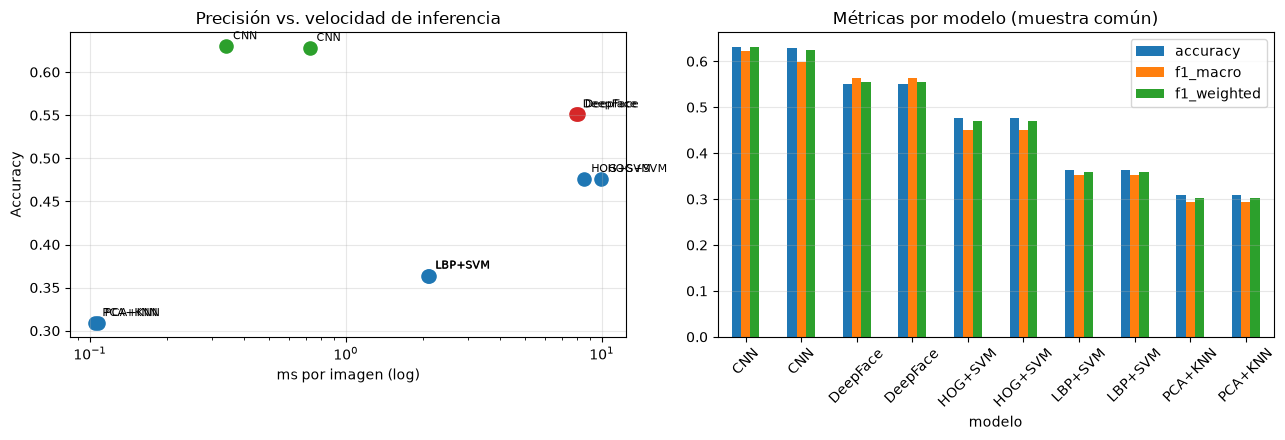

In [29]:
# --- Precisión vs. velocidad (muestra común) ---
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
colors = {"Clásico": "tab:blue", "CNN propia": "tab:green", "DeepFace": "tab:red"}
for _, r in df_sample.iterrows():
    ax[0].scatter(r.ms_img, r.accuracy, s=90, color=colors[r.familia])
    ax[0].annotate(r.modelo, (r.ms_img, r.accuracy), textcoords="offset points", xytext=(5, 5), fontsize=8)
ax[0].set_xscale("log"); ax[0].set_xlabel("ms por imagen (log)"); ax[0].set_ylabel("Accuracy")
ax[0].set_title("Precisión vs. velocidad de inferencia"); ax[0].grid(alpha=.3)

df_sample.set_index("modelo")[["accuracy", "f1_macro", "f1_weighted"]].plot(kind="bar", ax=ax[1], rot=45)
ax[1].set_title("Métricas por modelo (muestra común)"); ax[1].grid(alpha=.3, axis="y")
plt.tight_layout(); plt.show()

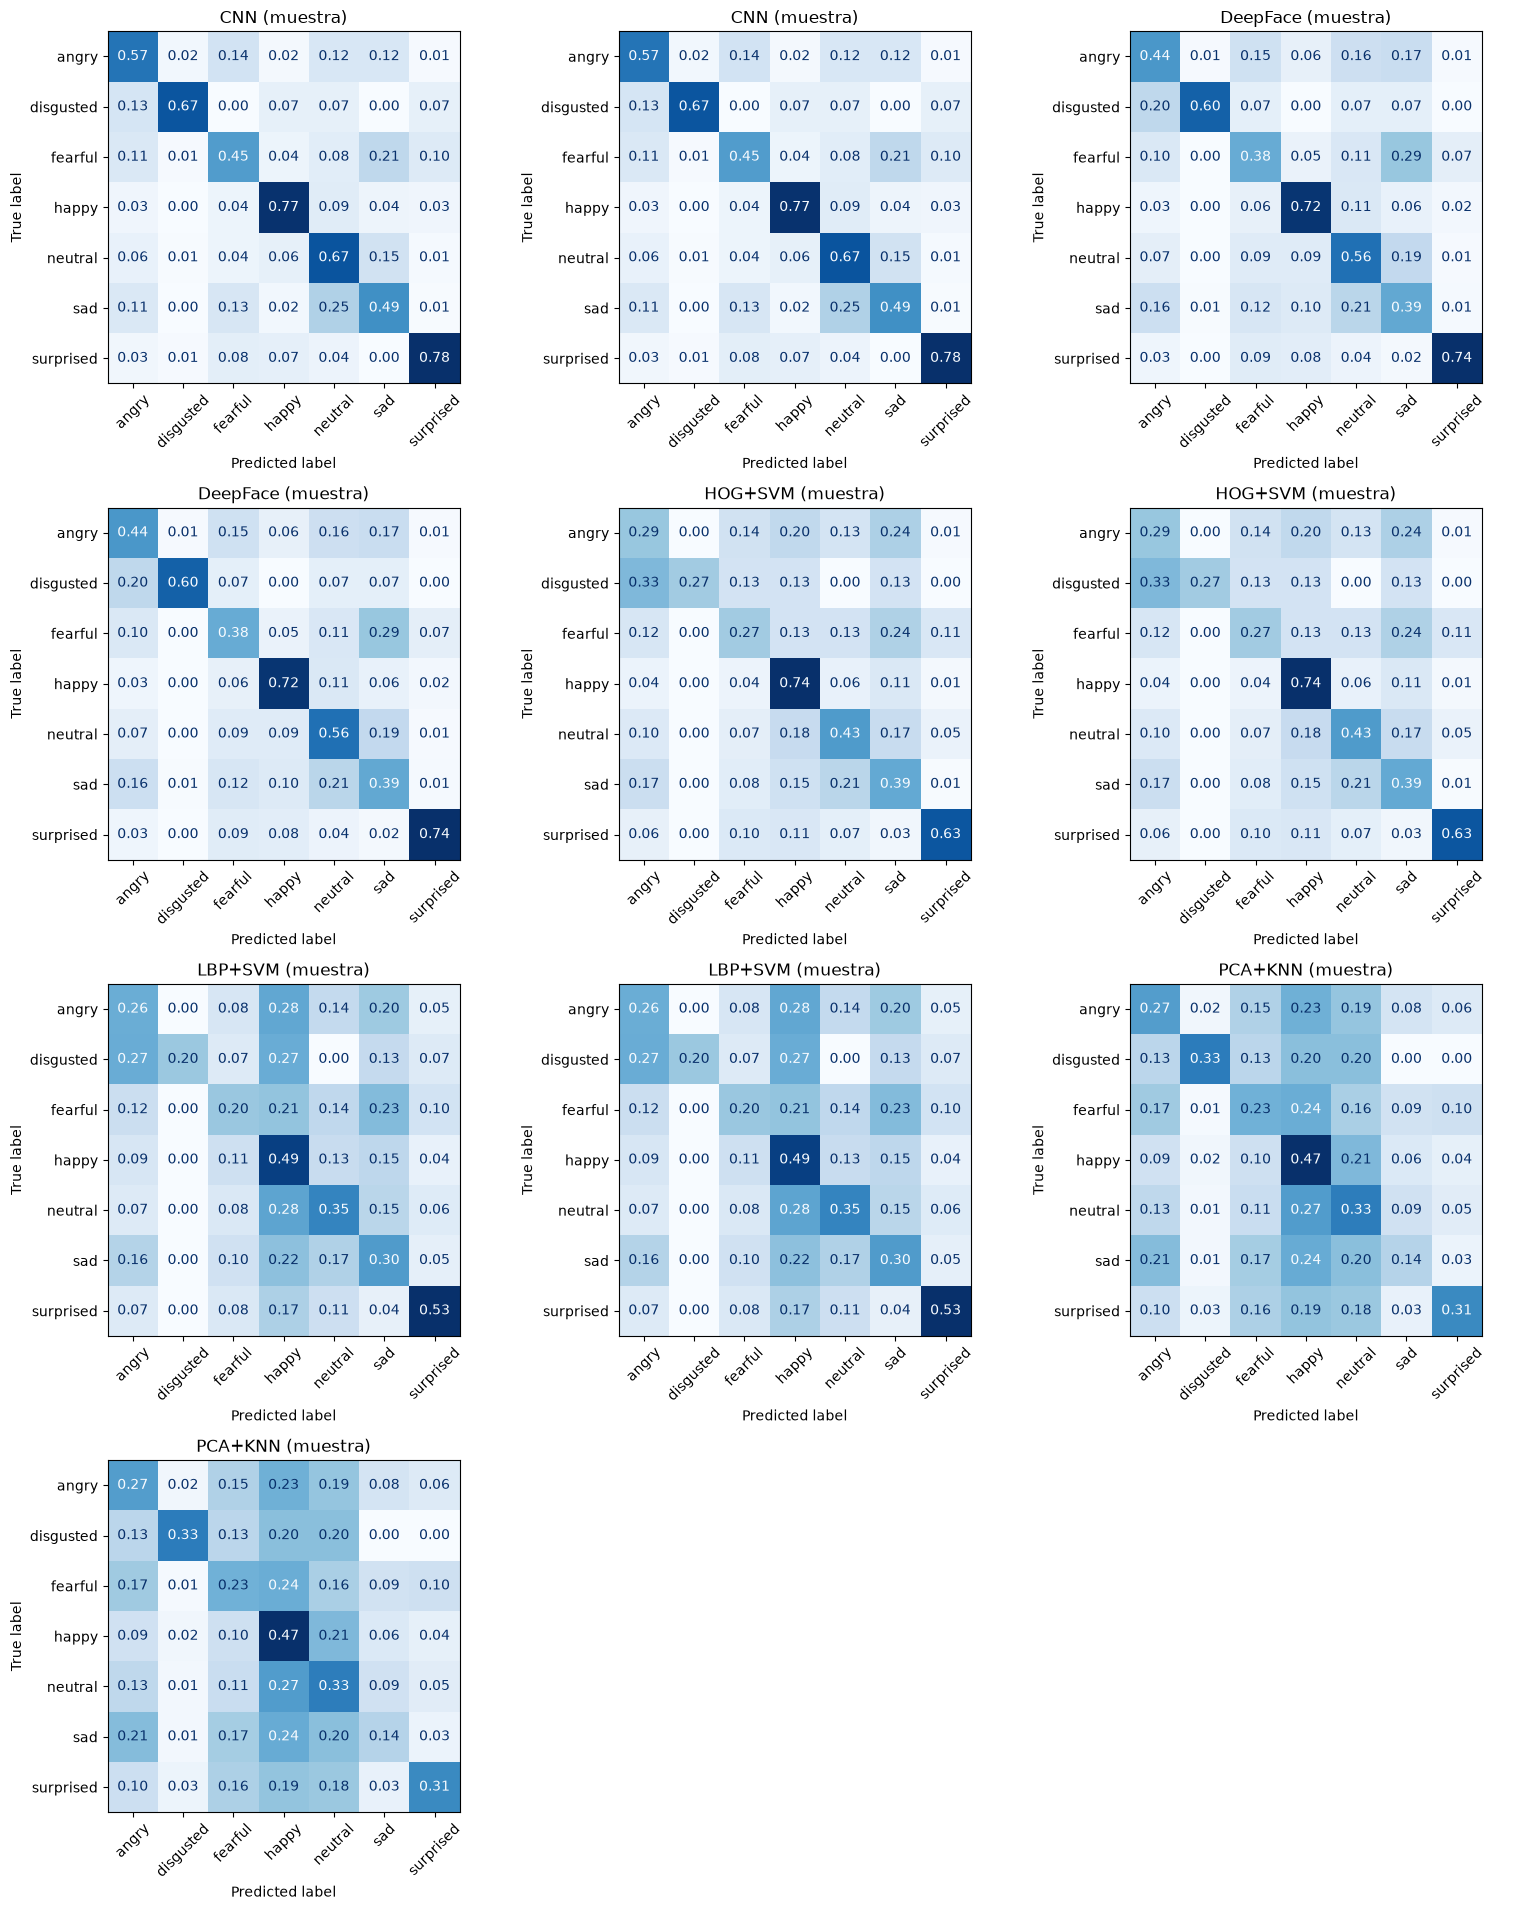

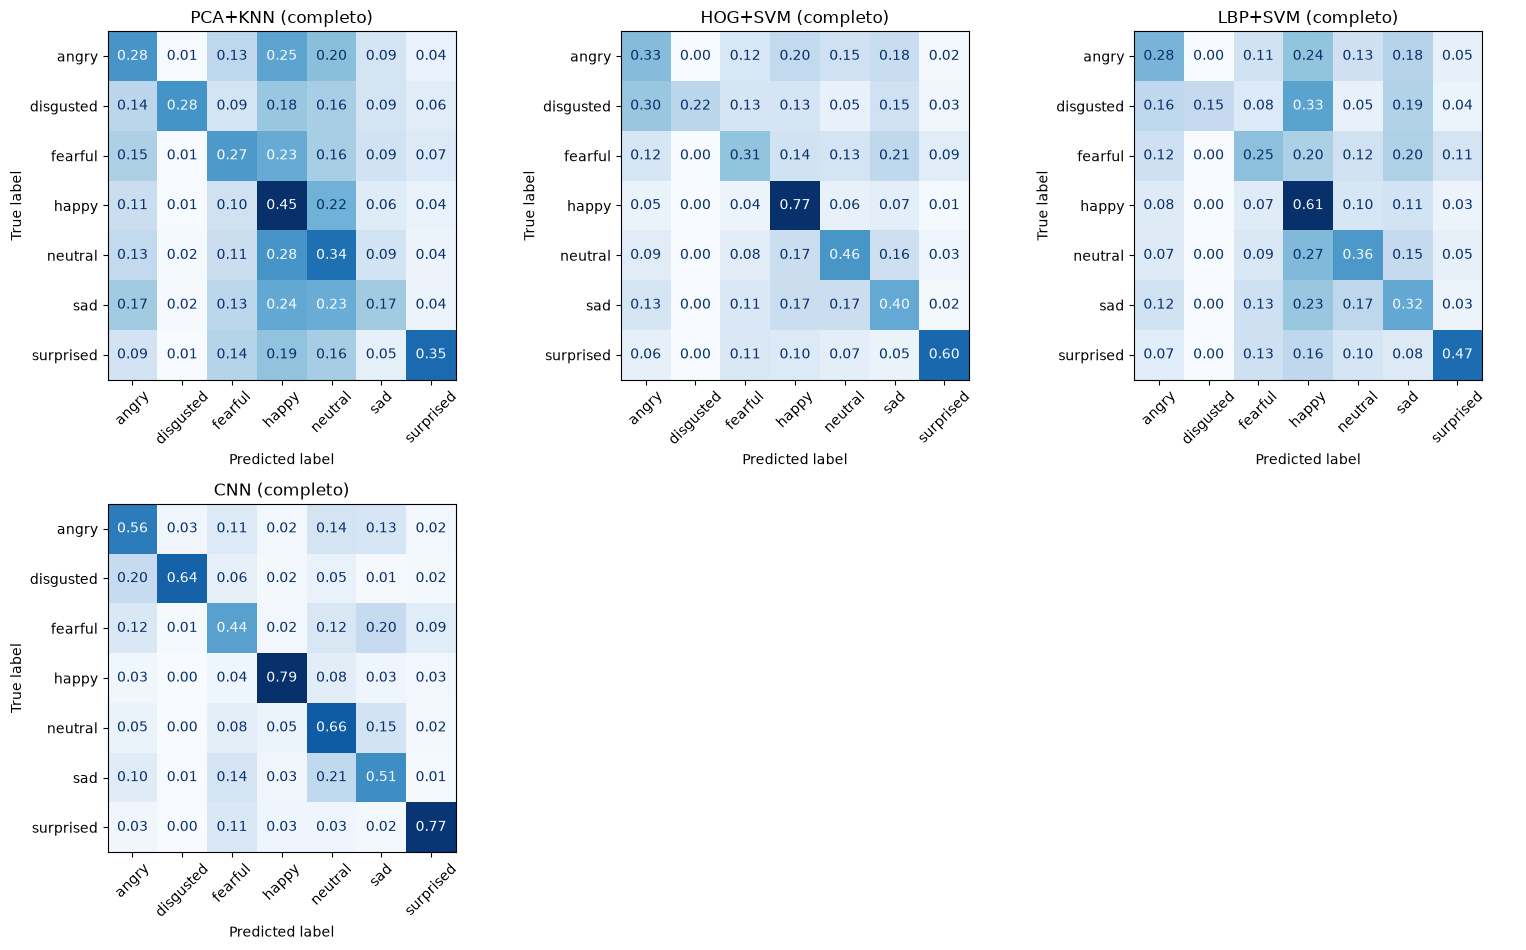

In [30]:
# --- Matrices de confusión ---
plot_confusions(list(df_sample.modelo), y_s, "muestra")                                   # todos, misma muestra
plot_confusions([n for n in PREDICT_FNS if n != "DeepFace"], y_test, "completo")         # propios, test completo

## 9. Comparativa final: DeepFace vs. nuestra CNN
Una sola comparativa directa, **solo DeepFace y el modelo entrenado**, sobre **la misma muestra estratificada de test**.
Como DeepFace procesa imagen a imagen, se añade también la latencia de la CNN con `batch=1` para que la velocidad sea comparable.

In [ ]:
FINAL = ["DeepFace", PRIMARY_CNN]
sub = df_sample.set_index("modelo")
fin = sub.loc[FINAL, ["accuracy", "f1_macro", "f1_weighted", "ms_img"]].copy()
row = fin.loc[PRIMARY_CNN].copy(); row["ms_img"] = CNN_LAT_BS1
fin.loc[f"{PRIMARY_CNN} (latencia batch=1)"] = row
print(f"=== {len(y_s)} imágenes de test (muestra estratificada común) ===")
display(fin.round(4))

full = df_full.set_index("modelo").loc[PRIMARY_CNN]
print(f"Referencia: {PRIMARY_CNN} en el TEST COMPLETO ({int(full.n)} imágenes): "
      f"accuracy={full.accuracy:.4f} | F1-macro={full.f1_macro:.4f}")

d_acc = (fin.loc[PRIMARY_CNN, "accuracy"] - fin.loc["DeepFace", "accuracy"]) * 100
d_f1  = (fin.loc[PRIMARY_CNN, "f1_macro"] - fin.loc["DeepFace", "f1_macro"]) * 100
ratio = fin.loc["DeepFace", "ms_img"] / CNN_LAT_BS1
print(f"\n{PRIMARY_CNN} vs DeepFace -> accuracy {d_acc:+.1f} pts | F1-macro {d_f1:+.1f} pts | "
      f"DeepFace tarda {ratio:.1f}x lo que la CNN con batch=1")

# --- F1 por clase ---
f1_cls = pd.DataFrame({n: f1_score(y_s, PREDS[(n, "muestra")], labels=range(N_CLASSES), average=None, zero_division=0)
                       for n in FINAL}, index=CLASS_NAMES)
ax = f1_cls.plot(kind="bar", figsize=(9, 4), rot=0, color=["tab:red", "tab:green"])
ax.set_title("F1 por clase (muestra común)"); ax.set_ylabel("F1"); ax.grid(alpha=.3, axis="y")
plt.tight_layout(); plt.show()

# --- Matrices de confusión lado a lado ---
plot_confusions(FINAL, y_s, "muestra", ncols=2)

=== 1000 imágenes de test (muestra estratificada común) ===


,accuracy,f1_macro,f1_weighted,ms_img
modelo,,,,
DeepFace,0.551,0.5637,0.5541,8.0620
DeepFace,0.551,0.5637,0.5541,7.9149
CNN,0.630,0.6229,0.6314,0.3405
CNN,0.628,0.5978,0.6250,0.7218


TypeError: int() argument must be a string, a bytes-like object or a real number, not 'Series'

## 10. Mejoras de nuestro modelo (por qué puntúa más que los demás)

La CNN no gana por una sola razón: es la suma de varias decisiones, todas medidas con **validación** (nunca con test).

**Frente a los modelos clásicos (PCA / HOG / LBP)**
* **Características aprendidas, no fijas.** HOG y LBP son descriptores diseñados a mano y PCA solo captura varianza global; la CNN aprende filtros específicos para expresiones (boca, cejas, arrugas) de extremo a extremo.
* **Arquitectura.** 4 bloques con doble convolución 3×3 (+ `BatchNormalization` + `MaxPooling2D`) dan un campo receptivo amplio con pocos parámetros; `GlobalAveragePooling` en lugar de `Flatten` reduce el sobreajuste.
* **Más datos efectivos.** El aumento de datos (flip horizontal, rotación ≈ ±11°, zoom ±10 %) crea variantes nuevas en cada época. Los clásicos ven solo las imágenes originales (y el SVM, un subconjunto).
* **Desbalanceo.** `class_weight` hace que *disgusted* pese más en la pérdida sin tirar datos. El experimento `BALANCE_TRAIN` permite comprobar el coste de igualar las clases submuestreando.
* **Optimización cuidada.** `AdamW` (weight decay), `ReduceLROnPlateau`, `EarlyStopping` con `restore_best_weights` y `ModelCheckpoint`: se queda con la mejor época según la validación.
* **Regularización calibrada.** Dropout creciente por bloque (0,10 → 0,25) y 0,40 en la cabeza: menos que la versión inicial, porque las curvas mostraban más infra-regularización que sobreajuste.
* **Preprocesado dentro del modelo.** El reescalado `/255` va en el propio `.keras`, así entrenamiento, evaluación y webcam usan exactamente la misma entrada.

**Frente a DeepFace**
* **Ventaja de dominio, no de arquitectura.** DeepFace es un modelo generalista preentrenado con otros datos y preprocesado; aquí recibe caras de 48×48 reescaladas y sin detector. Nuestra CNN se entrena con la distribución exacta de FER-2013 (48×48 en gris, su ruido y sus condiciones).
* DeepFace sigue siendo mucho más versátil (otros datasets, caras reales con detector, más acciones); la comparación solo mide este problema concreto.

**Protocolo justo**
* Misma partición con seed fija, hiperparámetros elegidos en validación, y el test usado **una sola vez** para el resultado final.
* La comparación directa con DeepFace usa la misma muestra estratificada para ambos.

**Límites y siguientes pasos**
* FER-2013 tiene etiquetas ruidosas (los humanos coinciden en torno al 65 %), así que el techo es bajo y *fearful* / *sad* seguirán siendo las clases más flojas.
* Mejoras que aún se pueden probar: TTA con flip, label smoothing, ensemble de varias seeds, y reentrenar con train+val usando el nº de épocas ya elegido.

### Notas para la memoria
* **Desbalanceo**: *disgusted* tiene muy pocas muestras; el F1-macro refleja mejor que la accuracy cómo se comporta en las clases minoritarias. La CNN y los SVM usan `class_weight`; KNN no lo admite.
* **`BALANCE_TRAIN`**: afecta a los modelos clásicos de este notebook. Para la CNN, entrena otra versión en `VC_P5_CNN_entrenamiento.ipynb` con `BALANCE_TRAIN=True` y aparecerá como `CNN balanceada`. Los resultados se guardan con sufijo (`_bal…`) para no pisar los anteriores.
* **SVM**: SVC-RBF entrenado con un subconjunto estratificado (`SVM_MAX_TRAIN`) por coste computacional; alternativa `SVM_KIND="linear"`.
* **Tiempos**: incluyen extracción de características + clasificación, con 1 hilo para los clásicos; la CNN se mide en batch y también con batch=1 (webcam).
* **DeepFace** se evalúa sin detector (`skip`) porque FER ya viene recortado; su modelo de emoción se entrenó con otras condiciones, por lo que es un *baseline* externo.
* **Webcam**: carga el `.keras`, recorta la cara (p. ej. con MediaPipe), pásala a gris, `cv2.resize(…, (48, 48))` y entra con forma `(1, 48, 48, 1)` y valores 0-255.